Dolaczenie modulow wykorzystywanych na potrzeby laboratorium:

In [1]:
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.applications.inception_v3 import preprocess_input
from tensorflow.keras.preprocessing.image import img_to_array, array_to_img, load_img
import numpy as np
import matplotlib.pyplot as plt
import glob, os

Ponizej zawarto definicje funkcji, ktore mozna wykorzystac do realizacji zadan laboratoryjnych oraz ich przyklady wywolania:

In [2]:
def read_img(filename, size):
    img = load_img(filename, target_size=size)
    img_array = img_to_array(img)
    img_array = preprocess_input(img_array)
    return img_array

# Example: img = read_img("img.jpg", (299, 299)) - wczytanie pliku img.jpg znajdujacego sie w tym samym folderze co notebook, 
# wynikowy rozmiar obrazu to 299x299 (i trzy kanaly - kodowanie rgb)

def create_dataset(main_folder_path, size):
    X = []
    y = []

    os.chdir(".")
    for file in glob.glob(main_folder_path + "/*/*.jp*"):
        X.append(read_img(file, size))
        y.append(file.split('\\')[1])
    X = np.asarray(X)
    y = np.asarray(y).astype('float32')
    return X, y

# Example: X, y = create_dataset("faces", (299, 299)) - wczytanie zbioru z folderu faces, w folderze znajduja sie dwa pofoldery - o nazwach 0 i 1, 
# a w nich zdjecia w formacie jpeg lub jpg, wynikowy rozmiar obrazów to 299x299 (i trzy kanaly - kodowanie rgb)

def plot_images(X, y, rows=2, cols=5, clustering=False, nntesting=False, y_pred=None):
    # rows - number of classes - 2
    # cols - number of instances in one class - 5 images per class
    fig, ax = plt.subplots(nrows=rows, ncols=cols, figsize=(14, 7))
    counter = 0
    for row in range(rows):
        for col in range(cols):
            ax[row][col].imshow(X[counter] * 0.5 + 0.5)
            if not clustering and not nntesting:
                ax[row][col].set_title(f"label:{y[counter]}")
            else:
                if clustering:
                    ax[row][col].set_title(f"cluster number:{y[counter]}")
                else:
                    ax[row][col].set_title(f"true:{y[counter]} predicted:{y_pred[counter]}")
            counter += 1
    plt.show()

# Example: 
# plot_images(X, y) - wyswietlenie zbioru treningowego/do grupowania z 10 elementami (5 na klase)
# plot_images(X_test, y_test, rows=2, cols=2) - wyswietlenie zbioru testowego z 4 elementami (2 na klase)
# plot_images(X, kmeans_prediction, clustering=True) - wywolanie do wyswietlenia wynikow grupowania
# plot_images(X_test, y_test, rows=2, cols=2, clustering=False, nntesting=True, y_pred=nn_pred.reshape(nn_pred.shape[0])) - wyswietlenie wynikow klasyfikacji dla zbioru testowego
# plot_images(X, y, clustering=False, nntesting=True, y_pred=nn_pred.reshape(nn_pred.shape[0])) - wyswietlenie wynikow klasyfikacji dla zbioru treningowego

Do zmiennych X, y oraz X_test, y_test nalezy wczytac obrazy ze stworzonych folderow. W X i X_test przechowywane są tabele reprezentujace obrazy, a w y i y_test - labele.

In [3]:
X, y = create_dataset("faces", (299, 299))
X_test, y_test = create_dataset("test", (299, 299))

Po wczytaniu tablice powinny miec nastepujace wymiary:

In [4]:
print(f"X shape: {X.shape}, y shape: {y.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")

X shape: (10, 299, 299, 3), y shape: (10,)
X_test shape: (4, 299, 299, 3), y_test shape: (4,)


Nastepnie nalezy wyswietlic obrazy w zbiorach:

Train:


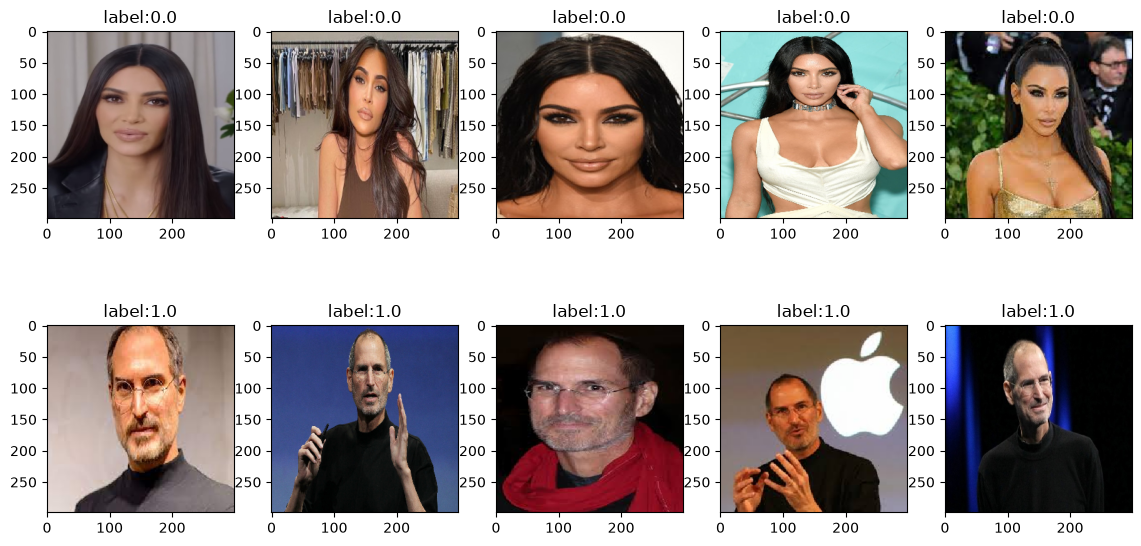

Test:


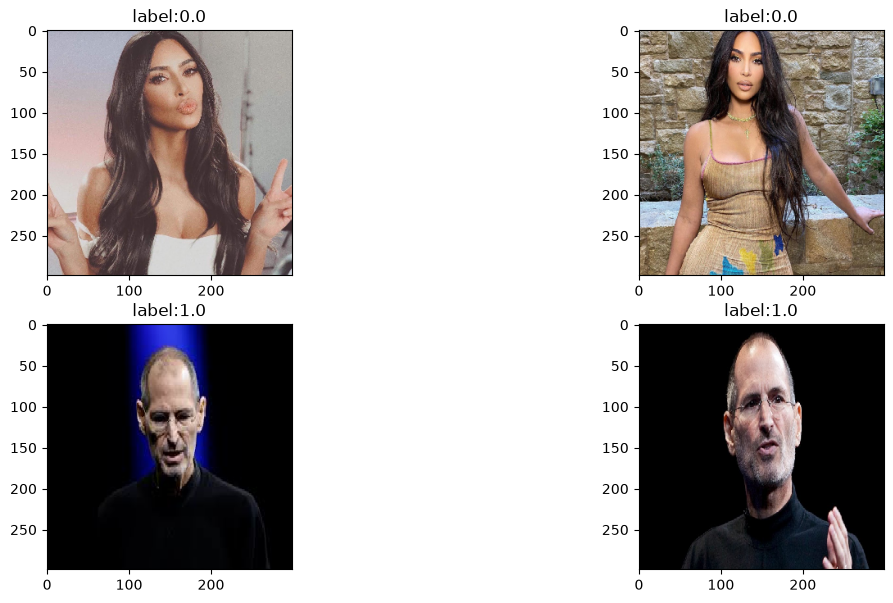

In [5]:
print("Train:")
plot_images(X, y)
print("Test:")
plot_images(X_test, y_test, rows=2, cols=2)

## **Grupowanie**

Wczytanie modelu (bedzie traktowany dalej jako model bazowy) i wyswietlenie jego podsumowania. Prosze skorzystac z modeli Xception lub InceptionV3.

In [6]:
from keras import Model
# Wczytanie wybranego modelu - przyklad - model Xception
model = InceptionV3()

model.summary()

Model: "inception_v3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 299, 299,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 149, 149,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 149, 149,  │         96 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 149, 149,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 147, 147,  │      9,216 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 147, 147,  │         96 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 147, 147,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 147, 147,  │     18,432 │ activation_1[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 147, 147,  │        192 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 147, 147,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 73, 73,    │          0 │ activation_2[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 73, 73,    │      5,120 │ max_pooling2d[0]… │
│                     │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 73, 73,    │        240 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 73, 73,    │          0 │ batch_normalizat… │
│ (Activation)        │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 71, 71,    │    138,240 │ activation_3[0][… │
│                     │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 71, 71,    │        576 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 71, 71,    │          0 │ batch_normalizat

 Total params: 23,851,784 (90.99 MB)

 Trainable params: 23,817,352 (90.86 MB)

 Non-trainable params: 34,432 (134.50 KB)

Funkcja summary nie wyswietla jednak nazw warstw, a jedynie typy. W celu wyswietlenia nazw, za pomoca ktorych mozna dostac sie do konkretnych warstw nalezy zapisac je do listy i wyswietlic:

In [7]:
# zapisanie do listy nazw warstw
model_layers = [layer.name for layer in model.layers]
print(model_layers)

['input_layer', 'conv2d', 'batch_normalization', 'activation', 'conv2d_1', 'batch_normalization_1', 'activation_1', 'conv2d_2', 'batch_normalization_2', 'activation_2', 'max_pooling2d', 'conv2d_3', 'batch_normalization_3', 'activation_3', 'conv2d_4', 'batch_normalization_4', 'activation_4', 'max_pooling2d_1', 'conv2d_8', 'batch_normalization_8', 'activation_8', 'conv2d_6', 'conv2d_9', 'batch_normalization_6', 'batch_normalization_9', 'activation_6', 'activation_9', 'average_pooling2d', 'conv2d_5', 'conv2d_7', 'conv2d_10', 'conv2d_11', 'batch_normalization_5', 'batch_normalization_7', 'batch_normalization_10', 'batch_normalization_11', 'activation_5', 'activation_7', 'activation_10', 'activation_11', 'mixed0', 'conv2d_15', 'batch_normalization_15', 'activation_15', 'conv2d_13', 'conv2d_16', 'batch_normalization_13', 'batch_normalization_16', 'activation_13', 'activation_16', 'average_pooling2d_1', 'conv2d_12', 'conv2d_14', 'conv2d_17', 'conv2d_18', 'batch_normalization_12', 'batch_norma

Wykorzystaj wyzej wczytany model podstawowy (np. Xception) i zbuduj model do ekstrakcji cech. Wykorzystaj parametr modelu input oraz funkcje get_layer (nazwe warstwy wybierz z listy warstw powyzej - ma to byc warstwa przed klasyfikatorem - splaszczajaca dane, np. average pooling) wraz z parametrem output. Wykorzystaj te dwie czesci i zbuduj model z pomoca funkcji Model. Model nazwac model_embeddings.

Hint:

https://keras.io/getting_started/faq/#how-can-i-obtain-the-output-of-an-intermediate-layer-feature-extraction

In [8]:
#TODO
#TODO
#TODO
model_embeddings = Model(inputs=model.input, outputs=model.get_layer("avg_pool").output)

Wygenerowanie cech (ekstrakcja cech) za pomoca stworzonego modelu:

In [9]:
pred_intermediate = model_embeddings.predict(X)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


Dokonaj predykcji (funkcja predict modelu) i wykorzystaj funkcje decode_predictions z keras.applications.imagenet_utils do zdekodowania 5 najbardziej prawdobodobych predykcji zwroconych przez model i wypisz je (dla wszystkich obrazkow w zbiorze).

In [10]:
#TODO
#TODO
#TODO
from keras.applications.imagenet_utils import decode_predictions
pred = model.predict(X)

for i, p in enumerate(decode_predictions(pred, top=5)):
    print(i, p)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
0 [('n04584207', 'wig', np.float32(0.6454169)), ('n04350905', 'suit', np.float32(0.03311986)), ('n03710637', 'maillot', np.float32(0.019249184)), ('n02669723', 'academic_gown', np.float32(0.018381113)), ('n04525038', 'velvet', np.float32(0.012761176))]
1 [('n04550184', 'wardrobe', np.float32(0.1555613)), ('n03770439', 'miniskirt', np.float32(0.06335198)), ('n03710637', 'maillot', np.float32(0.05614667)), ('n03595614', 'jersey', np.float32(0.043587983)), ('n03594734', 'jean', np.float32(0.04150588))]
2 [('n02892767', 'brassiere', np.float32(0.742593)), ('n03710637', 'maillot', np.float32(0.06255482)), ('n03314780', 'face_powder', np.float32(0.04100399)), ('n04584207', 'wig', np.float32(0.024110544)), ('n03710721', 'maillot', np.float32(0.018139388))]
3 [('n02892767', 'brassiere', np.float32(0.13900809)), ('n03710637', 'maillot', np.float32(0.12927628)), ('n03141823', 'crutch', np.float32(0.11757023)), ('n03710721', 'maillot', np.float32(0.1067093)), (

Zmiana ksztaltu tablicy z labelami (aby mozliwy byl zapis do DataFrame):

In [11]:
y_reshaped = y.reshape(y.shape[0], 1)
print(f"Shape of y_reshaped: {y_reshaped.shape}")

Shape of y_reshaped: (10, 1)


Z wykorzystaniem struktury DataFrame z bibioteki pandas cechy z sieci konwolucyjnej (embeddings/bottlneck features) sa zapisywane wraz z labelem do tablicy - df:

In [12]:
import pandas as pd
features = [f"feature_{i}" for i in range(0, pred_intermediate.shape[-1])]
features.append("label")
df_values = np.concatenate((pred_intermediate, y_reshaped), axis=-1)
df = pd.DataFrame(df_values, columns=features)

Wyswietlenie zawartosci df:

In [13]:
df

,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,...,feature_2039,feature_2040,feature_2041,feature_2042,feature_2043,feature_2044,feature_2045,feature_2046,feature_2047,label
0,0.063003,0.208741,0.489959,0.452934,0.178932,0.251472,0.487758,0.187480,0.391375,0.163417,...,0.251602,0.018723,1.290176,0.007850,0.316386,0.286096,0.718011,1.154843,0.237062,0.0
1,0.717700,0.401756,0.322132,0.405186,0.032994,0.244662,0.163789,0.868312,0.293605,0.448806,...,0.363654,0.064982,0.731754,0.132668,1.082430,0.008876,0.803231,2.597921,0.144064,0.0
2,0.162387,0.323750,0.006053,0.814508,0.219596,0.273545,0.066251,0.235716,0.350615,0.581434,...,0.649182,0.008380,1.115707,0.026477,0.339930,0.000000,0.353905,0.794815,0.279179,0.0
3,0.784311,0.979393,0.560104,0.815723,0.104259,0.025195,0.080966,0.224225,0.239852,0.288766,...,0.383863,0.032194,0.379494,0.460853,0.645085,0.416363,0.742319,0.708622,0.355614,0.0
4,0.750286,0.175925,1.164132,0.183662,0.475601,0.218818,0.190488,0.939589,0.243011,0.565325,...,0.411663,0.005738,0.448024,0.443664,0.122435,0.445546,0.465262,1.668391,0.033090,0.0
5,0.084491,0.136383,0.008459,0.356777,0.273325,0.169051,0.974899,0.458096,0.614840,0.763313,...,0.517072,0.054157,1.037223,0.013056,0.147055,0.000709,0.203755,0.007555,0.084102,1.0
6,0.557728,0.523678,0.067924,0.410650,0.351273,0.249190,0.827445,0.628488,0.045575,1.437114,...,0.183248,0.349671,1.858842,0.483057,0.739439,0.348657,1.027040,0.000000,0.361318,1.0
7,0.602087,0.020150,0.072716,0.208802,0.573217,0.208090,0.180734,0.157845,0.190429,1.063631,...,0.427508,0.471801,1.417968,0.371113,0.569026,0.249041,0.202762,0.206124,0.693477,1.0
8,0.443990,0.098073,0.434434,1.252800,0.148418,0.196109,1.119394,0.296748,0.272237,0.849190,...,0.977186,0.263199,1.318101,0.166294,0.429824,1.033531,0.497718,0.361916,0.162600,1.0
9,0.005967,0.029007,0.059743,0.569174,0.216302,0.212266,0.453021,0.203628,0.244476,0.891793,...,0.300862,0.191863,1.815707,0.516159,0.168196,0.187375,0.255227,0.375782,0.160036,1.0


Zapis do pliku csv:

In [14]:
df.to_csv("dataset_faces.csv", index=False)

Wykorzystac algorytm kmeans (KMeans z modulu cluster biblioteki sklearn), dopasowac go do danych przechowywanych w pred_intermediate, dokonac predykcji i jej wyniki zapisac do zmiennej kmeans_prediction. 

Hint:

https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html

In [15]:
# TODO
# TODO
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=2, random_state=0, n_init=10).fit(pred_intermediate)
kmeans_prediction = kmeans.predict(pred_intermediate)

Wyswietlic wyniki grupowania wraz z obrazami:

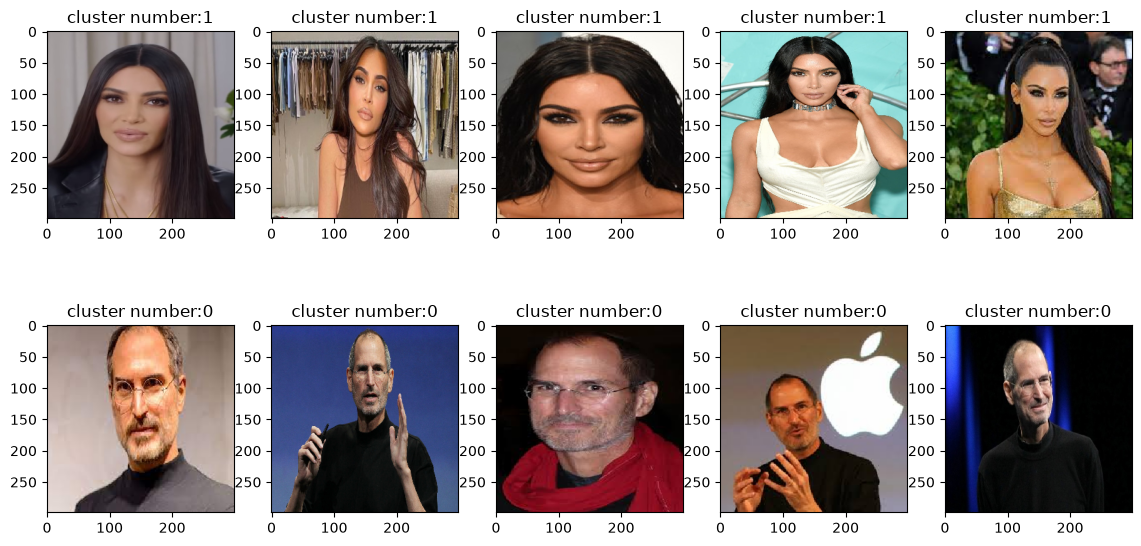

In [16]:
plot_images(X, kmeans_prediction, clustering=True)

Wyswietl workflow i rezultaty uzyskane w programie Orange:

Orange workflow


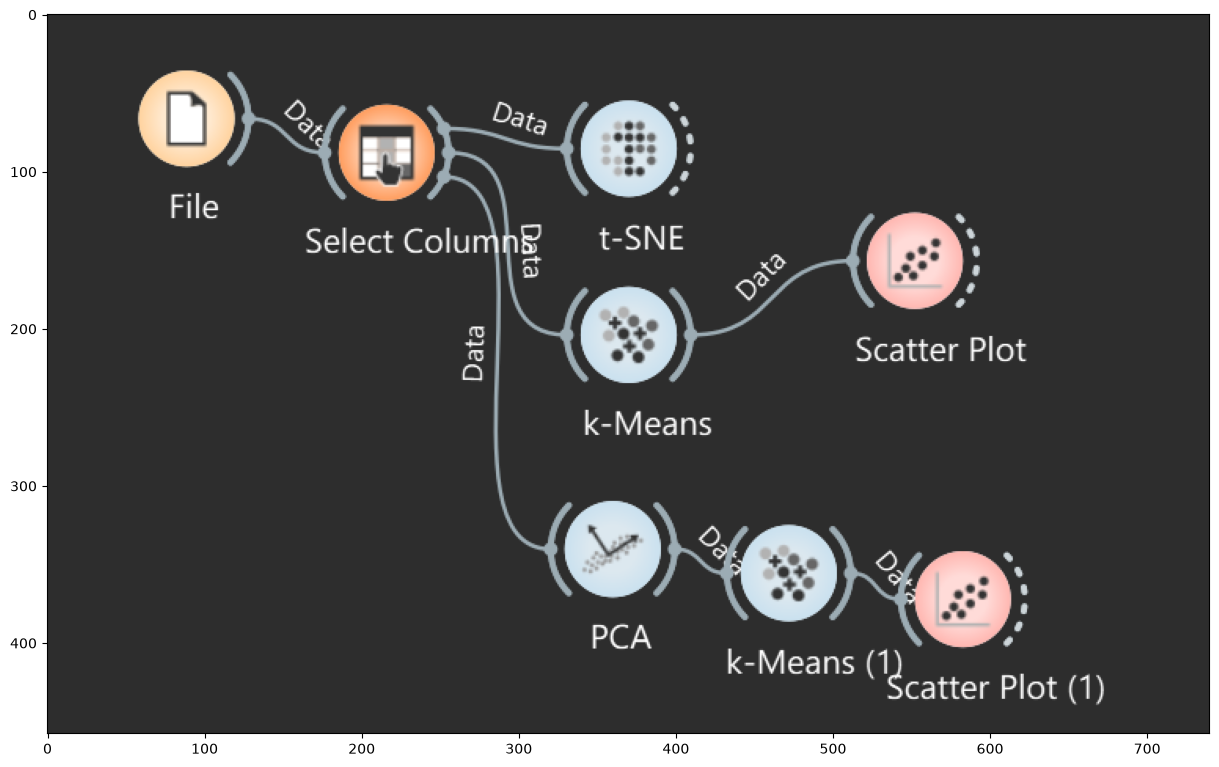

t-SNE results:


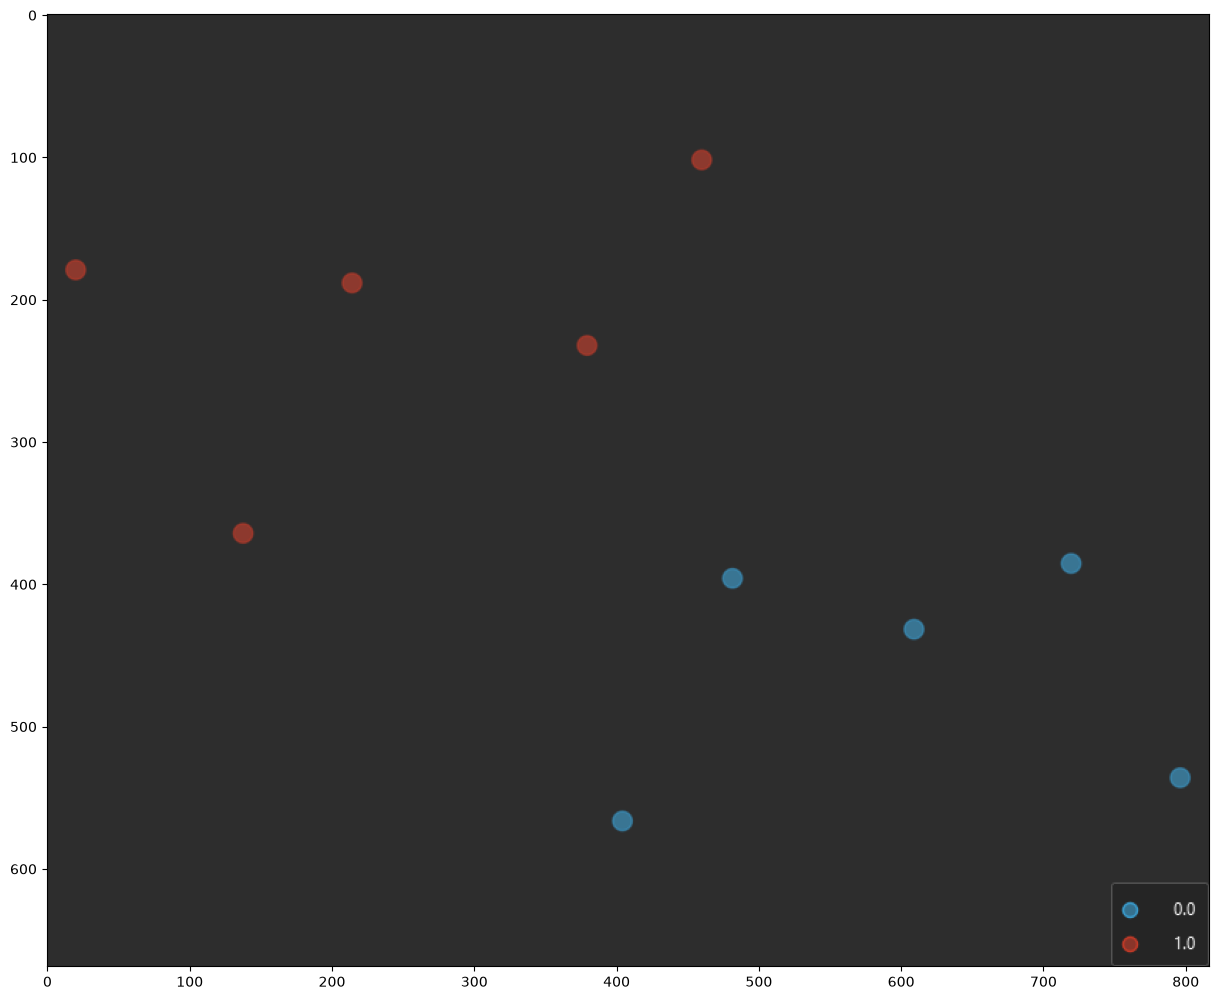

Raw kmenas results:


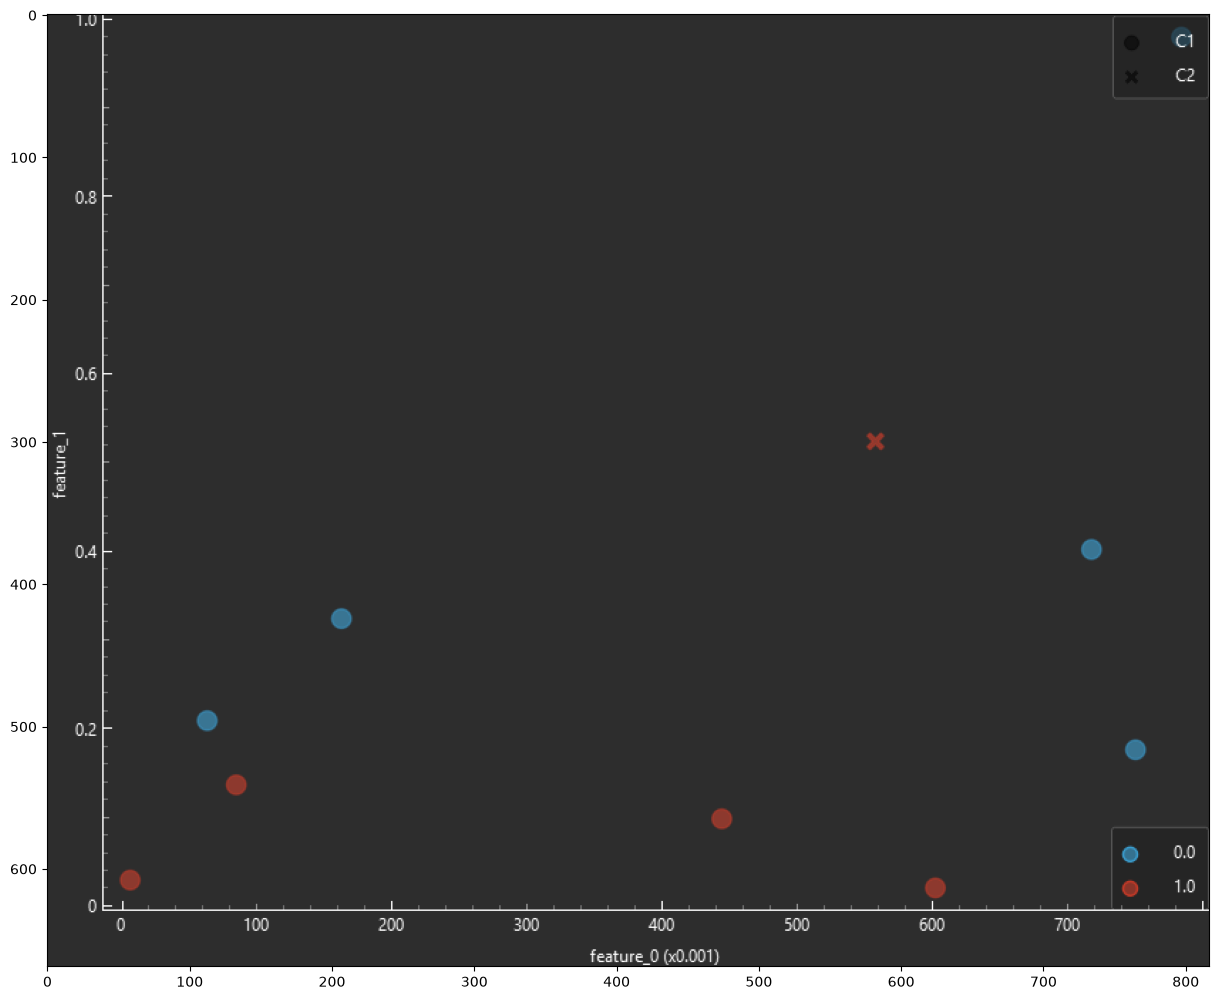

PCA + kmeans results:


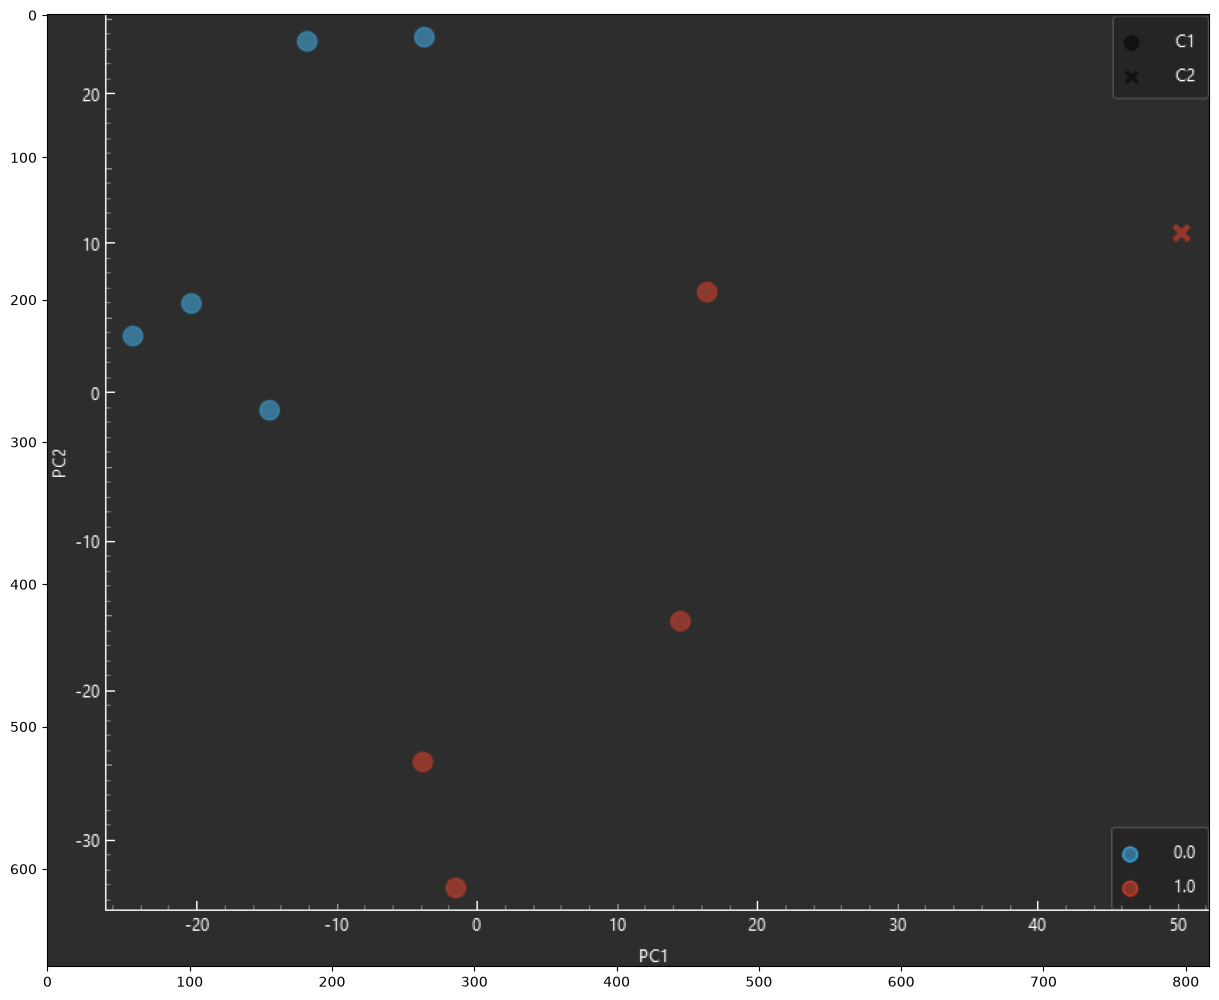

In [17]:
print("Orange workflow")
img = load_img("orangeworkflow.png")
img_array = img_to_array(img)/255.
plt.figure(figsize = (15,15))
plt.imshow(img_array)
plt.show()

print("t-SNE results:")
img = load_img("tsne.png")
img_array = img_to_array(img)/255.
plt.figure(figsize = (15,15))
plt.imshow(img_array)
plt.show()

print("Raw kmenas results:")
img = load_img("kmeans.png")
img_array = img_to_array(img)/255.
plt.figure(figsize = (15,15))
plt.imshow(img_array)
plt.show()

print("PCA + kmeans results:")
img = load_img("kmeanspca.png")
img_array = img_to_array(img)/255.
plt.figure(figsize = (15,15))
plt.imshow(img_array)
plt.show()

**TODO: Napisac krotkie wnioski:**

Wnioski: cechy z przedostatniej warstwy sieci (avg_pool, 2048 wartości) niosą informację pozwalającą odróżnić obie osoby. Widać to na t-SNE, gdzie obie klasy tworzą wyraźnie oddzielone grupy, oraz po PCA (2 komponenty), gdzie klasy układają się po przeciwnych stronach osi PC1 (z jednym zachodzącym punktem). Sam algorytm k-means (2 klastry) wypadł jednak słabo, zarówno na surowych cechach, jak i po PCA: wydzielił tylko jeden odstający obraz, a pozostałe 9 trafiło do jednego klastra, więc grupowanie nie odpowiada etykietom. Przyczyną jest mały zbiór (10 obrazów) i obecność punktu odstającego, który zdominował podział. Wizualizacje (t-SNE, PCA) lepiej oddają strukturę danych niż k-means.

## **Klasyfikacja**

Wczytac model bazowy (Xception lub InceptionV3) z parametrem include_top ustawionym na False (klasyfikator dla zbioru ImageNet jest "odcinany"). Ustawic odpowiedni rozmiar warstwy wejsciowej - (299, 299, 3), ustawic parametr weights na imagenet. Model nazwij base_model.

Hint (dla Xception):

https://keras.io/api/applications/xception/

inne modele (nie wszystkie modele sa bezposrednio dostepne w tensorflow.keras.applications):

https://keras.io/api/applications/

**Na potrzeby laboratorium prosze skorzytac z modeli Xception lun InceptionV3.**, oczywiscie mozna takze "pobawic" sie innymi, ale nie jest gwarantowana ich skutecznosc :)

In [18]:
# TODO
# TODO
# TODO
base_model = InceptionV3(include_top=False, weights="imagenet", input_shape=(299, 299, 3))

Sprawic aby parametry modelu bazowego **nie byly trenowane** - sprawdz parametr trainable modelu

Hint:

https://keras.io/guides/transfer_learning/

In [19]:
# TODO
base_model.trainable = False

Z wykorzystaniem modelu bazowego (np. Xception) stworzyc swoj model do klasyfikacji binarnej zdjec. Do stworzenia modelu wykorzystac nastepujace warstwy: Input, GlobalAveragePooling2D i Dense (w warstwie powinien sie znajdowac 1 neuron. Nalezy tu wykorzystac funkcje aktywacji sigmoid - wtedy na wyjsciu zostanie zwrocona liczba z zakresu 0, 1). Model koncowy nalezy stworzyc za pomoca funkcji Model, ktora jako argumenty przyjmuje warstwe wejsciowa i wyjsciowa. Ponizej przedstawiono wyglad modelu koncowego. Koncowy model nazwac new_model - aby mozliwe bylo korzystanie z dostarczonych pozniej komorek - swoj model takze wyswietlic.

Hint:

https://keras.io/guides/transfer_learning/

In [20]:
# TODO
# TODO
# TODO
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dense
inputs = Input(shape=(299, 299, 3))
x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)
outputs = Dense(1, activation="sigmoid")(x)
new_model = Model(inputs, outputs)


new_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 8, 8, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,804,833 (83.18 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 21,802,784 (83.17 MB)

Zbudowany model skompilować (funkcja compile, optymalizator: adam, funkcja straty: binary_crossentropy, metryka do sledzenia: accuracy) oraz przetrenowac (funkcja train, podajemy X i y jako argumenty, trening ma trwac 7 epok, ale mozna sprobowac takze inne liczby - nalezy obserwowac jak zmienia sie accuracy, w zbiorze znajduje sie tylko 10 probek, wiec liczba epok nie powinna byc zbyt duza - wtedy wystepuje szansa na przetrenowanie) - ponizej wynik

In [21]:
# TODO
# TODO
# TODO
new_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
new_model.fit(X, y, epochs=7)

Epoch 1/7
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step - accuracy: 0.5000 - loss: 0.7339
Epoch 2/7
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 576ms/step - accuracy: 0.7000 - loss: 0.6128
Epoch 3/7
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 846ms/step - accuracy: 0.8000 - loss: 0.5373
Epoch 4/7
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 628ms/step - accuracy: 0.9000 - loss: 0.4791
Epoch 5/7
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 577ms/step - accuracy: 0.9000 - loss: 0.4246
Epoch 6/7
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 757ms/step - accuracy: 1.0000 - loss: 0.3715
Epoch 7/7
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 600ms/step - accuracy: 1.0000 - loss: 0.3220


Predykcja za pomoca wytrenowanego modelu:

In [22]:
nn_pred_train = new_model.predict(X)
print("train raw:")
print(nn_pred_train)
nn_pred_train_binary = np.round(nn_pred_train)
print("train binary:")
print(nn_pred_train_binary)

nn_pred_test = new_model.predict(X_test)
print("test raw:")
print(nn_pred_test)
nn_pred_test_binary = np.round(nn_pred_test)
print("test binary:")
print(nn_pred_test_binary)

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
train raw:
[[0.3976916 ]
 [0.27309385]
 [0.27405173]
 [0.24040441]
 [0.26207548]
 [0.79858804]
 [0.9190883 ]
 [0.72383124]
 [0.80981064]
 [0.8075837 ]]
train binary:
[[0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
test raw:
[[0.2568444 ]
 [0.1843255 ]
 [0.74554306]
 [0.70653874]]
test binary:
[[0.]
 [0.]
 [1.]
 [1.]]


Wyznaczenie dokladnosci (accuracy) dla zbioru treningowego i testowego:

In [23]:
from sklearn.metrics import accuracy_score

train_accuracy = accuracy_score(y, nn_pred_train_binary)
test_accuracy = accuracy_score(y_test, nn_pred_test_binary)

Graficzna prezentacja wynikow i wyswietlenie dokladnosci:

train
accuracy: 1.0


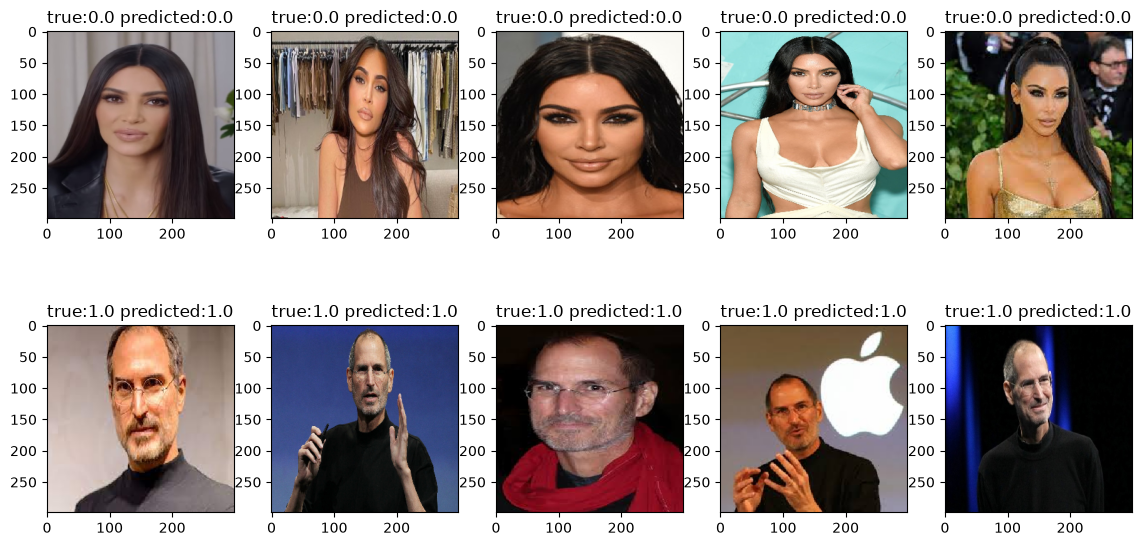

test
accuracy: 1.0


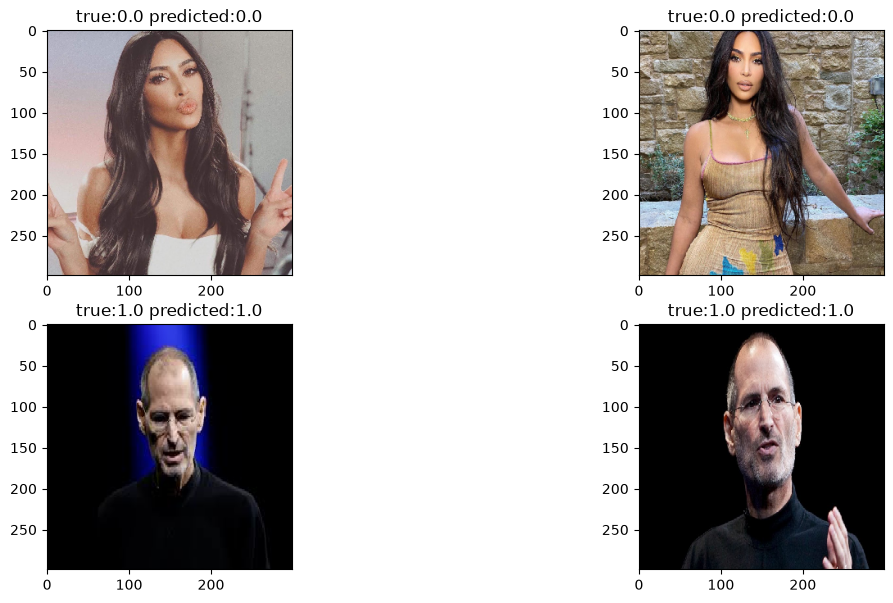

In [24]:
print("train")
print(f"accuracy: {train_accuracy}")
plot_images(X, y, rows=2, cols=5, clustering=False, nntesting=True, y_pred=nn_pred_train_binary.reshape(nn_pred_train_binary.shape[0]))
print("test")
print(f"accuracy: {test_accuracy}")
plot_images(X_test, y_test, rows=2, cols=2, clustering=False, nntesting=True, y_pred=nn_pred_test_binary.reshape(nn_pred_test_binary.shape[0]))

Wnioski: model bazowy z zamrożonymi wagami (InceptionV3) i dobudowany klasyfikator (GlobalAveragePooling2D + Dense) osiągnął accuracy 1.0 na zbiorze treningowym i testowym po 7 epokach. Cechy wyuczone na ImageNet są wystarczające do rozróżnienia dwóch klas nawet przy 10 próbkach treningowych.